# Paper 12: RoFormer: Enhanced Transformer with Rotary Position Embedding (RoPE)
**Authors**: Jianlin Su, Yu Lu, Shengfeng Pan, Bo Wen, Yunfeng Liu (2021)

---

## 1. The Historical Breaking Point: Absolute vs. Relative Positions
In the original Transformer (Vaswani et al., 2017), positions were injected **additively** into input token embeddings:
$$\tilde{\mathbf{x}}_i = \mathbf{x}_i + \mathbf{p}_i$$
- **Cross-term Entanglement**: Queries and keys expand as $(\mathbf{x}_m + \mathbf{p}_m)^T W_q^T W_k (\mathbf{x}_n + \mathbf{p}_n)$, mixing content and position.
- **Poor Length Extrapolation**: Absolute coordinates fail when sequences exceed the pretraining context window.
- **Attention Kernel Incompatibility**: Methods like T5 and Transformer-XL added relative distance bias matrices $b_{m - n}$ directly to the attention logits, breaking compatibility with fast fused kernels (FlashAttention).

## 2. The First-Principles Breakthrough: Complex Plane Rotation
Can we find an encoding function $\mathbf{f}(\mathbf{x}, m)$ applied **locally to queries and keys** such that their inner product depends strictly on the relative distance $(m - n)$?

In 2D geometry, rotation preserves inner products under relative angles:
$$\langle \mathbf{q} e^{i m \theta}, \mathbf{k} e^{i n \theta} \rangle = \text{Re}[\mathbf{q} \mathbf{k}^* e^{i (m - n) \theta}]$$
**The absolute positions $m$ and $n$ completely vanish!**

## 3. Fast Vectorized Form: `rotate_half`
$$\text{rotate\_half}(\mathbf{x}) = [-\mathbf{x}_{d/2:}, \mathbf{x}_{:d/2}]$$
$$\text{RoPE}(\mathbf{x}, m) = (\mathbf{x} \odot \cos(m \Theta)) + (\text{rotate\_half}(\mathbf{x}) \odot \sin(m \Theta))$$

In this notebook, you will develop and verify:
1. `rotate_half` and `apply_rotary_pos_emb`
2. `RotaryPositionalEmbedding` frequency caching
3. `RoPEMultiHeadAttention`
4. `RoFormerEncoderLayer` and `RoFormerEncoder`

---
## Setup & Autoreload

In [12]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from model import (
    rotate_half,
    apply_rotary_pos_emb,
    RotaryPositionalEmbedding,
    RoPEMultiHeadAttention,
    PositionwiseFeedForward,
    RoFormerEncoderLayer,
    RoFormerEncoder,
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch version: 2.14.1+cpu
CUDA available: False


---
## 1. Test `rotate_half`
Verify that 4 successive 90-degree rotations in the complex plane equal the identity transformation ($R^4 = I$).

In [13]:
x = torch.tensor([[1.0, 2.0, 3.0, 4.0]])
rot = rotate_half(x)
print("Original: ", x)
print("Rotated:  ", rot)  # Expected: [[-3.0, -4.0, 1.0, 2.0]]

rot4 = rotate_half(rotate_half(rotate_half(rotate_half(x))))
assert torch.allclose(rot4, x)
print("rotate_half 4-fold cyclic rotation PASSED!")

Original:  tensor([[1., 2., 3., 4.]])
Rotated:   tensor([[-3., -4.,  1.,  2.]])
rotate_half 4-fold cyclic rotation PASSED!


---
## 2. Verify Relative Position Invariance
The fundamental theoretical guarantee: Shifting both tokens by arbitrary offset $s$ does **NOT** alter their inner product:
$$\langle \text{RoPE}(\mathbf{q}, m), \text{RoPE}(\mathbf{k}, n) \rangle = \langle \text{RoPE}(\mathbf{q}, m + s), \text{RoPE}(\mathbf{k}, n + s) \rangle$$

In [14]:
torch.manual_seed(42)
d_k = 64
rope = RotaryPositionalEmbedding(dim=d_k, max_seq_len=256)

m, n, s = 12, 19, 37
cos, sin = rope(seq_len=100)

q = torch.randn(1, 1, 1, d_k)
k = torch.randn(1, 1, 1, d_k)

q_m = apply_rotary_pos_emb(q, cos[:, :, m:m+1, :], sin[:, :, m:m+1, :])
k_n = apply_rotary_pos_emb(k, cos[:, :, n:n+1, :], sin[:, :, n:n+1, :])
dot_original = (q_m * k_n).sum().item()

q_ms = apply_rotary_pos_emb(q, cos[:, :, m+s:m+s+1, :], sin[:, :, m+s:m+s+1, :])
k_ns = apply_rotary_pos_emb(k, cos[:, :, n+s:n+s+1, :], sin[:, :, n+s:n+s+1, :])
dot_shifted = (q_ms * k_ns).sum().item()

diff = abs(dot_original - dot_shifted)
print(f"Dot product at (m={m}, n={n}):         {dot_original:.6f}")
print(f"Dot product at (m+s={m+s}, n+s={n+s}): {dot_shifted:.6f}")
print(f"Difference: {diff:.2e}")
assert diff < 1e-5
print("Relative Position Invariance PASSED!")

Dot product at (m=12, n=19):         15.749668
Dot product at (m+s=49, n+s=56): 15.749666
Difference: 1.91e-06
Relative Position Invariance PASSED!


---
## 3. Visualize Natural Long-Range Decay
Plot the theoretical correlation curve $\sum_{i=1}^{d/2} \cos((m - n) \theta_i)$ as relative distance increases.

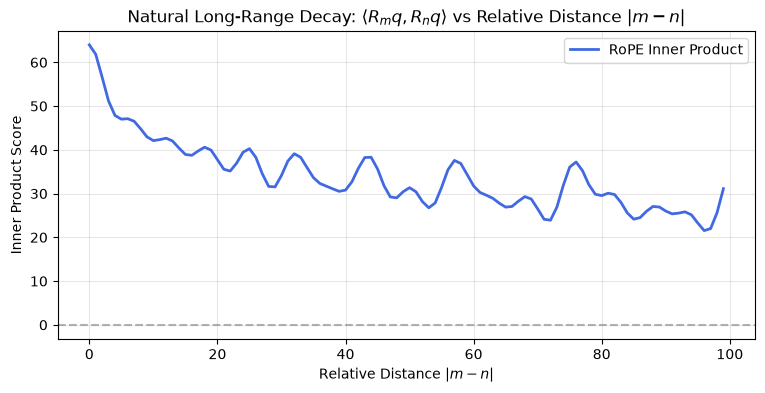

In [18]:
d_k = 64
seq_len = 100
rope = RotaryPositionalEmbedding(dim=d_k, max_seq_len=seq_len)
cos, sin = rope(seq_len=seq_len)

q = torch.ones(1, 1, seq_len, d_k)
q_rot = apply_rotary_pos_emb(q, cos, sin)
scores = torch.matmul(q_rot, q_rot.transpose(-2, -1)).squeeze().detach().cpu().numpy()

offsets = list(range(seq_len))
correlations = [scores[0, t] for t in offsets]

plt.figure(figsize=(9, 4))
plt.plot(offsets, correlations, color='royalblue', linewidth=2, label='RoPE Inner Product')
plt.axhline(0, color='gray', linestyle='--', alpha=0.6)
plt.title(r'Natural Long-Range Decay: $\langle R_m q, R_n q \rangle$ vs Relative Distance $|m - n|$')
plt.xlabel('Relative Distance $|m - n|$')
plt.ylabel('Inner Product Score')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

---
## 4. Test RoPEMultiHeadAttention & Causal Masking

In [16]:
mha = RoPEMultiHeadAttention(d_model=64, num_heads=4, dropout=0.0)
mha.eval()

B, T = 2, 8
x = torch.randn(B, T, 64)
causal_mask = torch.tril(torch.ones(T, T, dtype=torch.bool))

out, weights = mha(x, mask=causal_mask)
print("Output shape:  ", out.shape)      # (2, 8, 64)
print("Weights shape: ", weights.shape)  # (2, 4, 8, 8)

upper_tri_max = torch.triu(weights, diagonal=1).max().item()
print(f"Max attention weight in upper triangle: {upper_tri_max:.2e}")
assert upper_tri_max < 1e-4
print("RoPEMultiHeadAttention Causal Masking PASSED!")

Output shape:   torch.Size([2, 8, 64])
Weights shape:  torch.Size([2, 4, 8, 8])
Max attention weight in upper triangle: 0.00e+00
RoPEMultiHeadAttention Causal Masking PASSED!


---
## 5. Single Batch Overfit: RoFormer Sequence Reconstruction

Step 15 | Loss: 0.7983
Step 30 | Loss: 0.1751
Step 45 | Loss: 0.0827
Step 60 | Loss: 0.0542


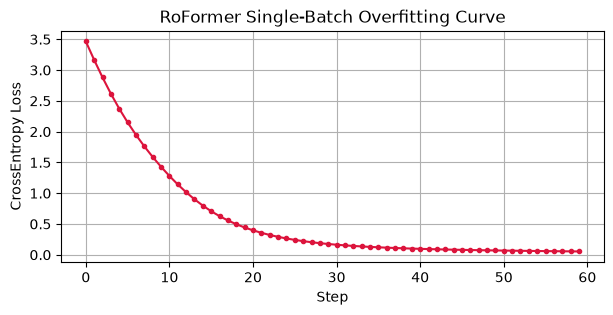

RoFormer single batch overfit PASSED! Final loss: 0.0542


In [17]:
torch.manual_seed(42)
vocab_size, d_model = 30, 64
model = RoFormerEncoder(
    vocab_size=vocab_size,
    d_model=d_model,
    num_layers=2,
    num_heads=4,
    d_ff=128,
    dropout=0.0,
)
head = nn.Linear(d_model, vocab_size)
optimizer = optim.Adam(list(model.parameters()) + list(head.parameters()), lr=1e-3)
criterion = nn.CrossEntropyLoss()

input_ids = torch.randint(1, vocab_size, (2, 8))
targets = input_ids.clone()

losses = []
for step in range(60):
    optimizer.zero_grad()
    hidden = model(input_ids)
    logits = head(hidden)
    loss = criterion(logits.view(-1, vocab_size), targets.view(-1))
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (step + 1) % 15 == 0:
        print(f"Step {step+1:2d} | Loss: {loss.item():.4f}")

plt.figure(figsize=(7, 3))
plt.plot(losses, marker='o', markersize=3, color='crimson')
plt.xlabel('Step')
plt.ylabel('CrossEntropy Loss')
plt.title('RoFormer Single-Batch Overfitting Curve')
plt.grid(True)
plt.show()

assert losses[-1] < 0.1
print(f"RoFormer single batch overfit PASSED! Final loss: {losses[-1]:.4f}")